## Step 1 : Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    RocCurveDisplay,
)

## Step 2 : Generate synthetic dataset (or load via pd.read_csv)

In [2]:
x,y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    random_state=42
)

## Step 3 : Train Test Split( 80% train, 20% test )

In [3]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=42, stratify=y
)

## Step 4 : Model training and comparison

In [4]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

In [6]:
results = {}
for name, model in models.items():
    model.fit(x_train, y_train)
    preds = model.predict(x_test)
    probs = model.predict_proba(x_test)[:, 1]
    acc = accuracy_score(y_test, preds)
    results[name] = {"model": model, "accuracy": acc, "preds": preds, "probs": probs}
    print(f"{name} Accuracy: {acc:.4f}")

Logistic Regression Accuracy: 0.8200
Decision Tree Accuracy: 0.8450
Random Forest Accuracy: 0.8900


## Step 5 : Confusion matrix for random forest

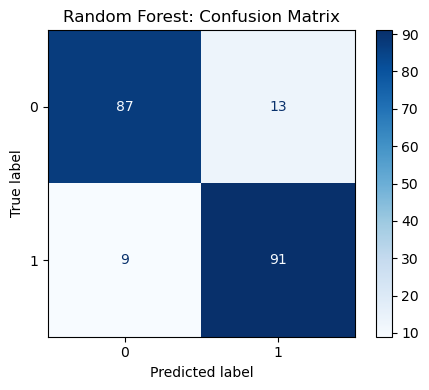

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_test, results["Random Forest"]["preds"])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1]).plot(ax=ax, cmap="Blues")
plt.title("Random Forest: Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 6 : ROC curve comparison across all models

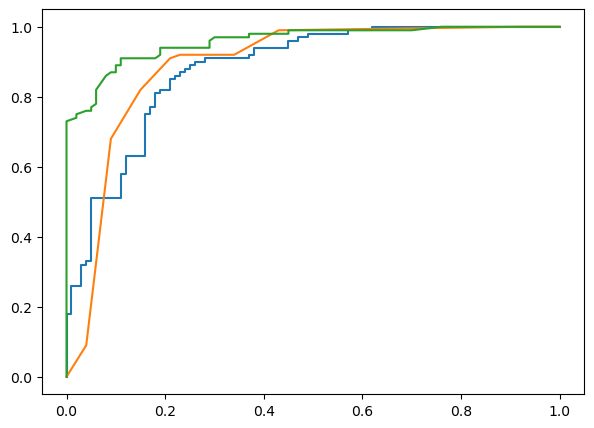

In [8]:
plt.figure(figsize=(7, 5))
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res["probs"])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")



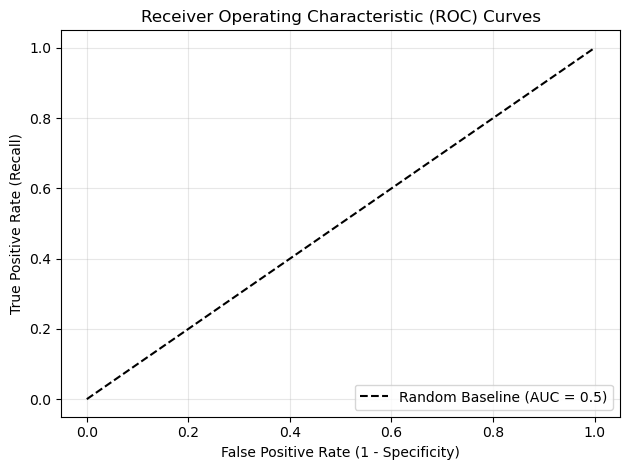

In [9]:
plt.plot([0, 1], [0, 1], "k--", label="Random Baseline (AUC = 0.5)")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Receiver Operating Characteristic (ROC) Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()